In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/loan_data_clean.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
1,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
2,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
3,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
4,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2


In [2]:
# Overall default rate
print(round(df["loan_status"].mean() * 100, 2), "%")

21.87 %


**Insight:** About 21.87% of borrowers defaulted, so roughly 1 in 5 loans is at risk.

loan_grade
A     9.96
B    16.32
C    20.76
D    59.05
E    64.49
F    70.54
G    98.44
Name: loan_status, dtype: float64


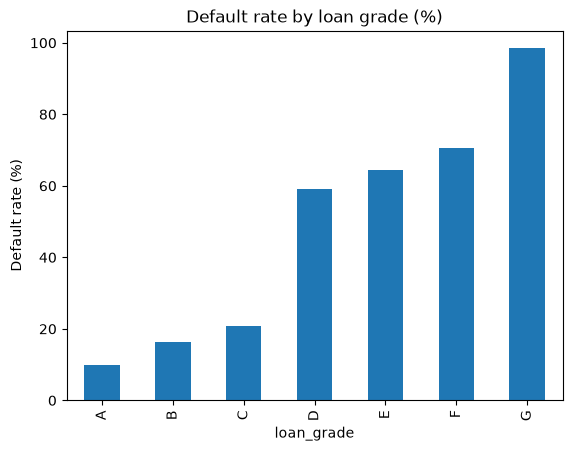

In [3]:
# Default rate by loan grade
grade = df.groupby("loan_grade")["loan_status"].mean().mul(100).round(2)
print(grade)
grade.plot(kind="bar", title="Default rate by loan grade (%)")
plt.ylabel("Default rate (%)")
plt.show()

**Insight:** Default rate rises sharply as loan grade gets worse. Grade A defaults at 9.96%, while grade G reaches 98.44%. The biggest jump is between grade C (20.76%) and grade D (59.05%).

**Recommendation:** The lender should be much stricter on grades D to G, where more than half of the loans default.

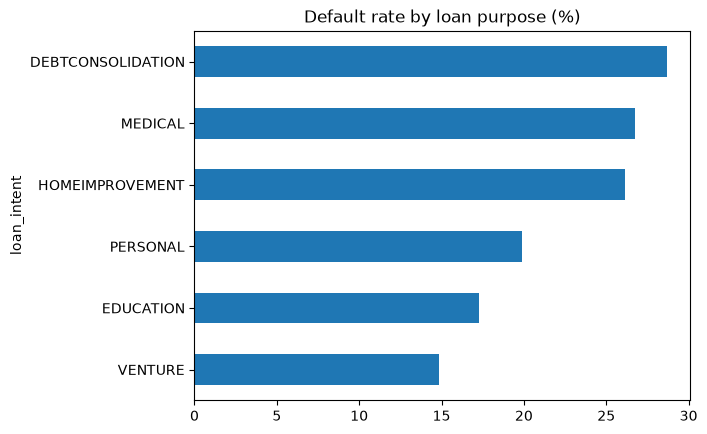

In [4]:
# Default rate by loan purpose
intent = df.groupby("loan_intent")["loan_status"].mean().mul(100).round(2).sort_values()
intent.plot(kind="barh", title="Default rate by loan purpose (%)")
plt.show()

**Insight:** [highest purpose] has the highest default rate at [X]%, while [lowest purpose] has the lowest at [Y]%. Loan purpose matters, but the gap between purposes is much smaller than the gap between loan grades.

**Recommendation:** Apply stricter checks to [highest purpose] loans, such as lower limits or a higher minimum credit grade.

person_home_ownership
MORTGAGE    12.62
OTHER       31.13
OWN          7.49
RENT        31.61
Name: loan_status, dtype: float64


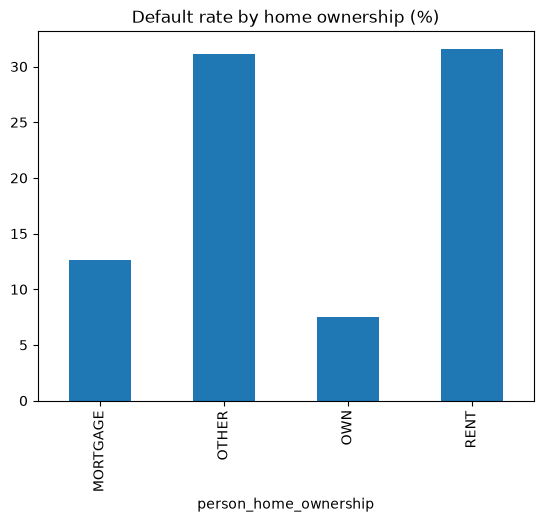

In [5]:
# Default rate by home ownership
home = df.groupby("person_home_ownership")["loan_status"].mean().mul(100).round(2)
print(home)
home.plot(kind="bar", title="Default rate by home ownership (%)")
plt.show()

**Insight:** Renters default far more often than homeowners. RENT borrowers default at about 31%, compared with about 12.6% for MORTGAGE and about 7.5% for OWN. Home ownership is a strong signal of repayment risk.

**Recommendation:** Treat renters as higher risk, for example by checking their loan-to-income ratio and loan amount more closely before approval.



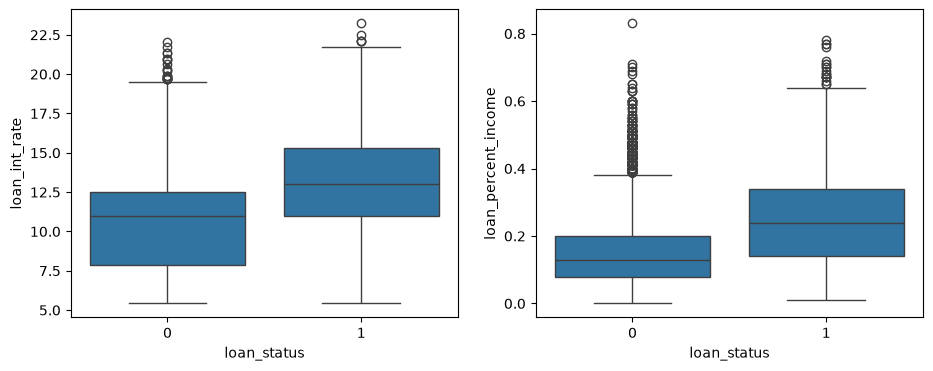

In [6]:
# Interest rate and loan-to-income ratio: defaulters vs non-defaulters
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x="loan_status", y="loan_int_rate", data=df, ax=axes[0])
sns.boxplot(x="loan_status", y="loan_percent_income", data=df, ax=axes[1])
plt.show()

**Insight:** Defaulters pay higher interest rates, with a median of [X]% compared with [Y]% for borrowers who repaid. They also borrow a larger share of their income, with a median loan-to-income ratio of [A] versus [B]. Loans that are expensive and large relative to income are more likely to default.

**Recommendation:** Flag applications with a high loan-to-income ratio and a high interest rate for extra review, or cap the loan amount relative to income.

In [9]:
# Default rate by age group and income group
df["age_group"] = pd.cut(df["person_age"], [19, 25, 35, 45, 100])
df["income_group"] = pd.qcut(df["person_income"], 4, labels=["Low", "Mid", "High", "Very high"])
print(df.groupby("age_group", observed=True)["loan_status"].mean().mul(100).round(2))
print(df.groupby("income_group", observed=True)["loan_status"].mean().mul(100).round(2))

age_group
(19, 25]     23.13
(25, 35]     20.69
(35, 45]     20.68
(45, 100]    22.29
Name: loan_status, dtype: float64
income_group
Low          39.75
Mid          21.41
High         17.14
Very high     9.14
Name: loan_status, dtype: float64


**Insight:** Income is a much stronger signal of default risk than age. Default rates are similar across age groups, ranging only from 20.68% (ages 36 to 45) to 23.13% (ages 20 to 25). By income, the gap is large: the lowest income group defaults at 39.75%, while the highest income group defaults at only 9.14%. Default rate falls steadily as income rises.

**Recommendation:** Treat low-income applicants as higher risk, for example by capping loan amounts relative to income and reviewing their loan-to-income ratio more closely. Age alone should not be used to decide approvals.

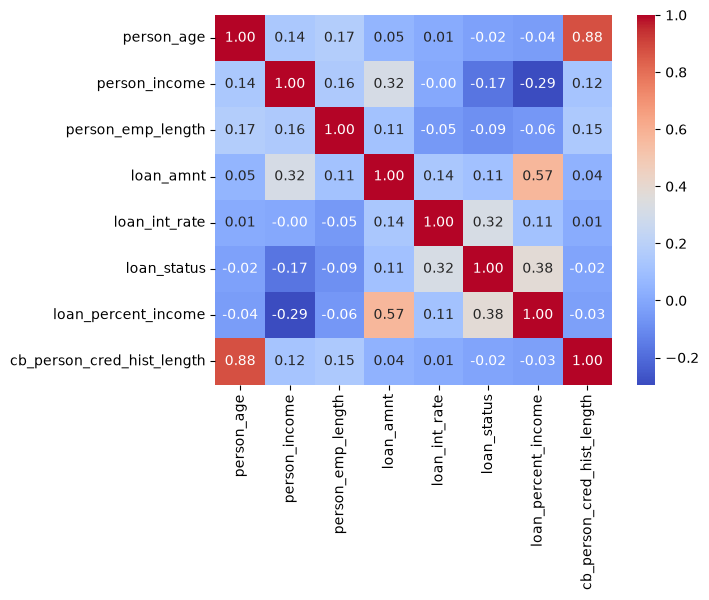

In [13]:
# Correlation heatmap
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

**Insight:** The factors most linked to default are the loan-to-income ratio (0.38) and the interest rate (0.32). Higher values of both go with a higher chance of default. Income has a negative link (-0.17), meaning higher-income borrowers default less. Age (-0.02) and credit history length (-0.02) have almost no link to default.

Two other patterns stand out. Age and credit history length are very strongly correlated with each other (0.88), so they carry almost the same information. Loan amount and loan-to-income ratio are also strongly linked (0.57), which is expected because the ratio is built from the loan amount.

**Recommendation:** Focus risk rules on loan-to-income ratio, interest rate and income. If building a model later, use only one of age and credit history length, because they overlap. Correlation shows a link, not a cause.